In [3]:
import numpy as np
import pandas as pd
import pickle
import gzip
import matplotlib.pyplot as plt

# Librerie per Motif e Shapelets
import stumpy
from aeon.classification.shapelet_based import RDSTClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.cluster import KMeans
from sktime.clustering.k_means import TimeSeriesKMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

try:
    from tslearn.shapelets import ShapeletModel
    from tslearn.utils import to_time_series_dataset
except ImportError:
    print("tslearn non trovata. Puoi installarla con !pip install tslearn")

import warnings
warnings.filterwarnings('ignore')

print("Caricamento dataset normalizzato (Dataset-wise)...")
ts_data = pd.read_pickle('ts_datasetwise_normalized.pkl.gz')
print(f"Trovate {len(ts_data)} serie storiche.")


tslearn non trovata. Puoi installarla con !pip install tslearn
Caricamento dataset normalizzato (Dataset-wise)...
Trovate 4437 serie storiche.


# Analisi Motifs e Shapelets (Denoised, Unstandardized)
Seguendo le direttive architetturali e i feedback ricevuti, in questo notebook analizziamo i dati **denoised** ma **non standardizzati** a livello di istanza, al fine di preservare l'intensità assoluta del movimento (energia e varianza reali dei pazienti).

In [25]:
# Caricamento del dataset standardizzato globale (dataset-wise, con media mobile)
with gzip.open("ts_datasetwise_normalized.pkl.gz", "rb") as f:
    ts_denoised = pickle.load(f)

print(f"Caricate {len(ts_denoised)} Time Series standardizzate.")

Caricate 4437 Time Series standardizzate.


## Preparazione Array per i Modelli
Estraiamo la feature `enmo` (intensità del movimento) e dividiamo in Train e Test set in modo stratificato rispetto al target `sii_binary`.

Numero di serie in Train: 3105
Numero di serie in Test: 1332


## Fase 1: Motifs e Discords (Matrix Profile)
Usiamo i medoidi estratti precedentemente nel modulo di clustering per osservare visivamente i pattern più frequenti e le anomalie.

In [26]:
# --- CONFIGURAZIONE GLOBALE ---
m = 8                          # Window size (es. 16 campionamenti = 8 ore se step=30min)
target_features = ['enmo'] # 'anglez'        # Variabile su cui calcolare il Matrix Profile (es. 'enmo', 'anglez', 'light')

k_clusters_motif = 3            # Numero di cluster desiderati per l'analisi dei Motif DTW
k_clusters_multi = 4            # Numero di cluster per l'analisi Multivariata Dataset-wise

top_k_motifs = 2                # Quanti Motif estrarre per ogni time series
top_k_discords = 2              # Quanti Discord estrarre per ogni time series

n_shapelets = 3                 # Numero di Shapelet da estrarre

# Variabile di supporto per stampare le etichette di tempo automaticamente
h_str = f"{m/2:g} ore"
print("Parametri configurati correttamente!")


Parametri configurati correttamente!


In [26]:
medoid_idx = [418, 478, 2439]
#medoid_idx = [3987, 69, 2439]
for x in medoid_idx:
    print(ts_denoised[x])

            X         Y         Z      enmo    anglez  non-wear_flag  \
0   -0.324360  0.501878 -2.107424 -0.690813 -2.211415            0.0   
1   -0.388878  0.501789 -2.108629 -0.689304 -2.198903            0.0   
2   -0.154313  0.417926 -2.145115 -0.688564 -2.306277            0.0   
3    0.189017  0.248597 -0.474407 -0.538667 -0.553430            0.0   
4    0.603149 -0.499815  1.326166 -0.335693  1.362715            0.0   
..        ...       ...       ...       ...       ...            ...   
195  0.030903  0.121756  1.363082  2.138881  1.306406            0.0   
196  0.708438  0.439264  1.246117  1.867273  1.226439            0.0   
197  0.861785  1.166231  1.203672  1.305860  1.183463            0.0   
198  0.678573  2.041141  0.985021  0.663361  0.939865            0.0   
199  0.334227  1.174504  1.098973  0.457868  1.048299            0.0   

        light  battery_voltage  weekday  quarter  relative_date_PCIAT    id  \
0    0.125591         0.257132      2.0      2.0        


ANALISI SULLA FEATURE: enmo


--- ANALISI DEL MEDOIDE 3846 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(26), np.int64(39), np.int64(76), 108]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [79 64]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



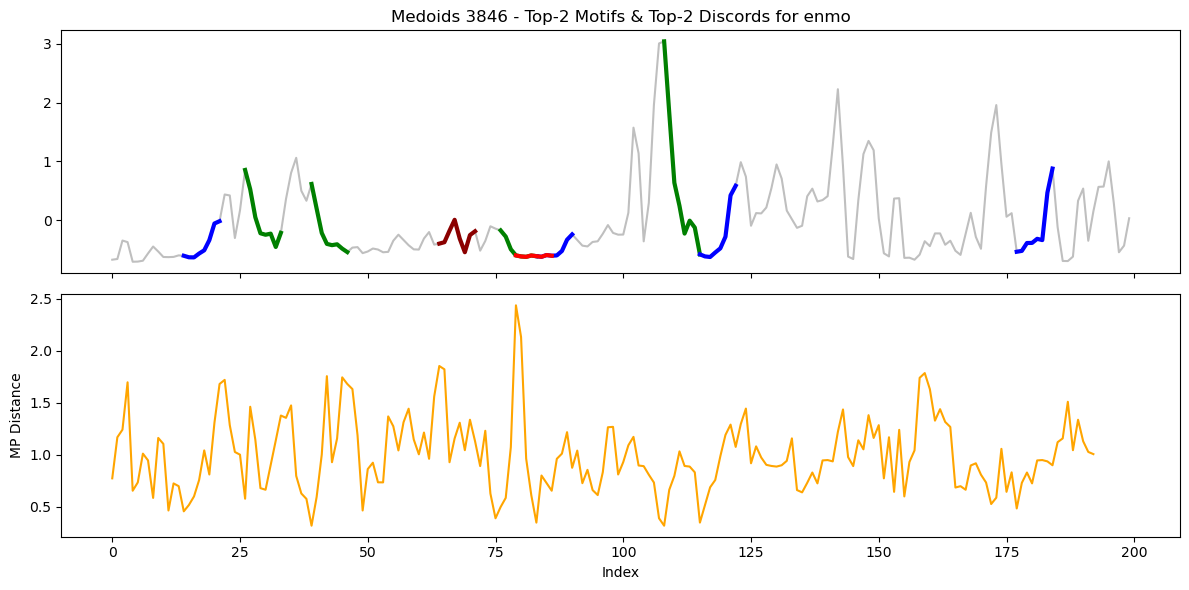


--- ANALISI DEL MEDOIDE 4386 (enmo) ---
Top-2 Motifs found. Example Top-1 at indices: [np.int64(150), 172]
   -> This means that the 4 ore blocks starting at these indices are nearly identical (routines).
Top-2 Discords found at indices: [ 91 126]
   -> The 4 ore windows starting at these steps are the most unique and anomalous in the series.



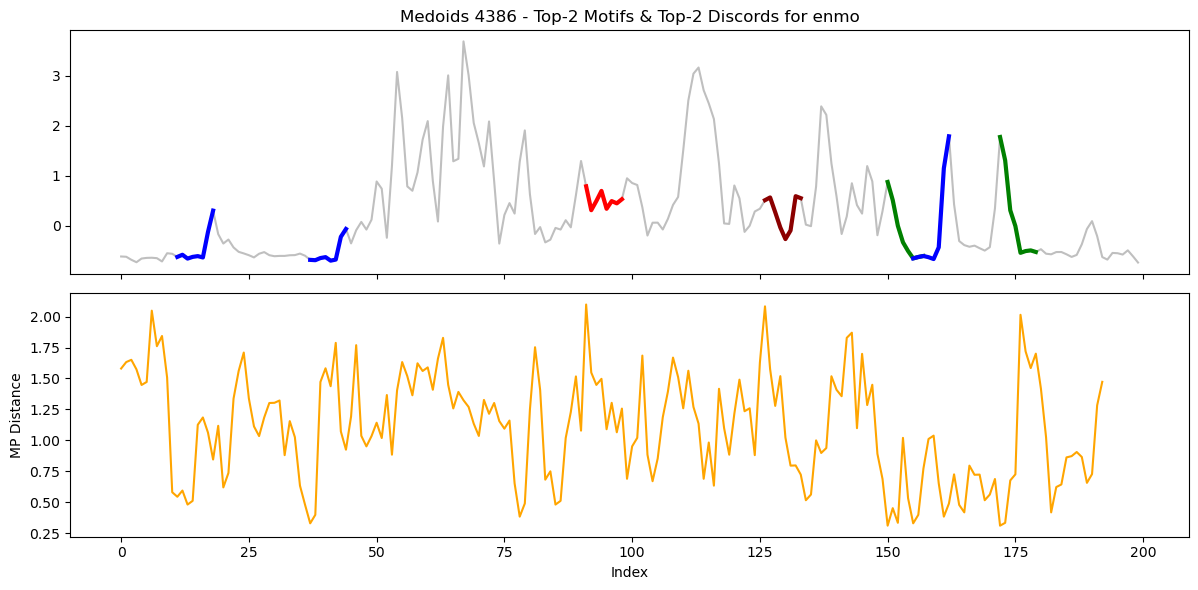

In [27]:
from matrixprofile import motifs
from matrixprofile.discords import discords
medoid_idx=[3846, 4386]
#medoid_idx = [1583, 1606, 1248]
medoids = [ts_denoised[i] for i in medoid_idx]

for target_feature in target_features:
    print(f"\n{'='*50}\nANALISI SULLA FEATURE: {target_feature}\n{'='*50}\n")
    
    for i, ts_df in enumerate(medoids):
        ts_medoide = ts_df[target_feature].values.astype(np.float64)

        # Calcoliamo il MP con stumpy per avere la matrice base
        mp_full = stumpy.stump(ts_medoide, m)
        mp_dist = mp_full[:, 0].astype(np.float64)
        mpi = mp_full[:, 1].astype(np.int64)

        # Estrattore Motifs tramite matrixprofile-ts come richiesto
        mo, mod = motifs.motifs(ts_medoide, (mp_dist, mpi), max_motifs=top_k_motifs)
        
        # Estrattore Discords tramite matrixprofile-ts come richiesto
        anoms = discords(mp_dist, ex_zone=int(m/2), k=top_k_discords)

        print(f"\n--- ANALISI DEL MEDOIDE {medoid_idx[i]} ({target_feature}) ---")
        if len(mo) > 0:
            print(f"Top-{len(mo)} Motifs found. Example Top-1 at indices: {mo[0]}")
            print(f"   -> This means that the {h_str} blocks starting at these indices are nearly identical (routines).")
        
        if len(anoms) > 0:
            print(f"Top-{len(anoms)} Discords found at indices: {anoms}")
            print(f"   -> The {h_str} windows starting at these steps are the most unique and anomalous in the series.\n")

        # Configurazione struttura subplots originale: 1 per le TS con Motifs/Discords, 1 per il Matrix Profile
        fig, axs = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
        
        # PLOT DEI MOTIFS E DISCORDS INSIEME
        axs[0].plot(ts_medoide, label=f"Time Series ('{target_feature}')", color='gray', alpha=0.5)
        axs[0].set_title(f"Medoids {medoid_idx[i]} - Top-{top_k_motifs} Motifs & Top-{top_k_discords} Discords for {target_feature}")
        
        # Plot Motifs
        colors_mo = ['g', 'b', 'black', 'm', 'y'][:max(1, len(mo))]

        for motif_group, d, c in zip(mo, mod, colors_mo):
            for idx in motif_group:
                m_shape = ts_medoide[idx : idx + m]
                axs[0].plot(range(idx, idx + m), m_shape, color=c, lw=3)
                
        # Plot Discords (in rosso)
        colors_anom = ['r', 'darkred', 'salmon', 'orange', 'k'][:max(1, len(anoms))]
        for a, c in zip(anoms, colors_anom):
            a_shape = ts_medoide[a : a + m]
            axs[0].plot(range(a, a + m), a_shape, color=c, lw=3)
            
        #axs[0].legend(loc='upper right')

        # PLOT DELLA MATRIX PROFILE DISTANCE (Valli e Picchi)
        axs[1].plot(mp_dist, color='orange')
        axs[1].set_ylabel('MP Distance')
        axs[1].set_xlabel('Index')
        
        plt.tight_layout()
        plt.show()


In [28]:
'''import matplotlib.pyplot as plt

# Recupero delle due serie dal dataset z-score
sano_waveform = motif_shapes_z_only[3846]  # Soggetto 3846 (SII 0)
rischio_waveform = motif_shapes_z_only[4386]  # Soggetto 4386 (SII 1)

plt.figure(figsize=(8, 4))
plt.plot(sano_waveform, color='royalblue', linewidth=2.5, label='Sano (SII=0) - Soggetto 3846')
plt.plot(rischio_waveform, color='crimson', linewidth=2.5, linestyle='--', label='A Rischio (SII=1) - Soggetto 4386')

plt.title("Analisi Contrastiva del Medoide nel Cluster 1 (Sedentario/Transitorio)", fontsize=11, fontweight='bold')
plt.ylabel("Standardized ENMO (Z-score)")
plt.xlabel("Time steps (relative inside 4-hour motif)")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()'''

'import matplotlib.pyplot as plt\n\n# Recupero delle due serie dal dataset z-score\nsano_waveform = motif_shapes_z_only[3846]  # Soggetto 3846 (SII 0)\nrischio_waveform = motif_shapes_z_only[4386]  # Soggetto 4386 (SII 1)\n\nplt.figure(figsize=(8, 4))\nplt.plot(sano_waveform, color=\'royalblue\', linewidth=2.5, label=\'Sano (SII=0) - Soggetto 3846\')\nplt.plot(rischio_waveform, color=\'crimson\', linewidth=2.5, linestyle=\'--\', label=\'A Rischio (SII=1) - Soggetto 4386\')\n\nplt.title("Analisi Contrastiva del Medoide nel Cluster 1 (Sedentario/Transitorio)", fontsize=11, fontweight=\'bold\')\nplt.ylabel("Standardized ENMO (Z-score)")\nplt.xlabel("Time steps (relative inside 4-hour motif)")\nplt.grid(True, alpha=0.3)\nplt.legend(loc="upper right")\nplt.tight_layout()\nplt.show()'


STRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)
ANCHOR FEATURE: enmo

1. Dynamic extraction and Local Normalization (Z-score) of Top-2 Motifs...
Created dataset of 8874 augmented motif feature vectors (dimension: 15) for enmo.

2. Executing KMeans Feature-Based (K=3) with Euclidean distance...


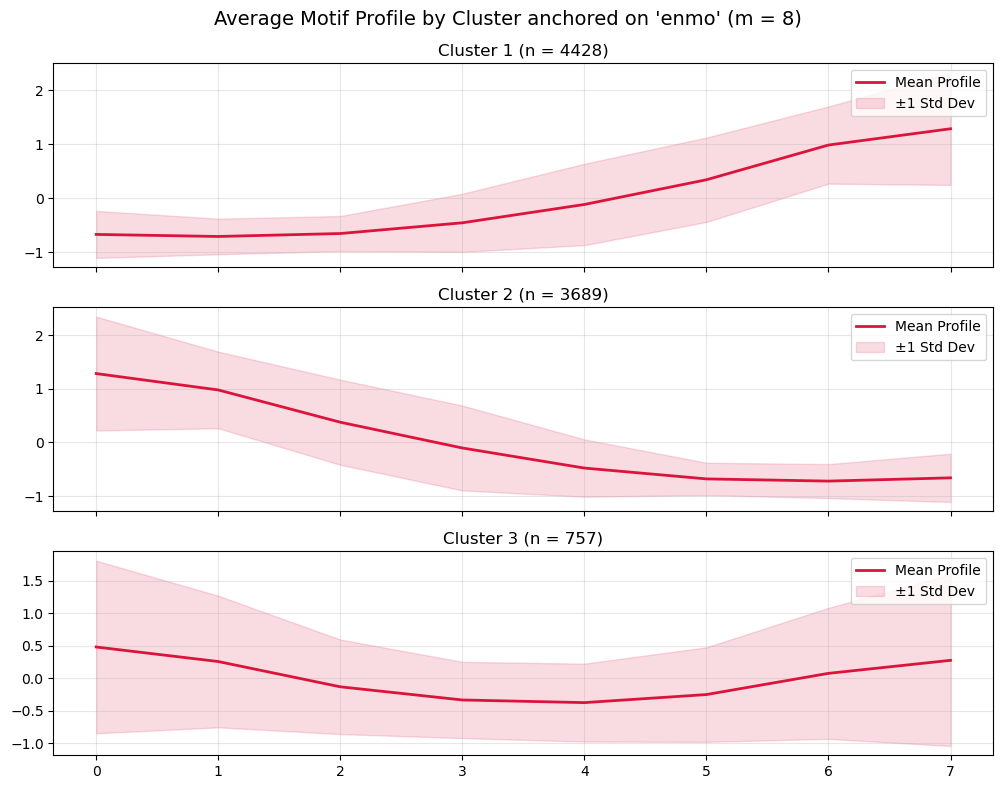

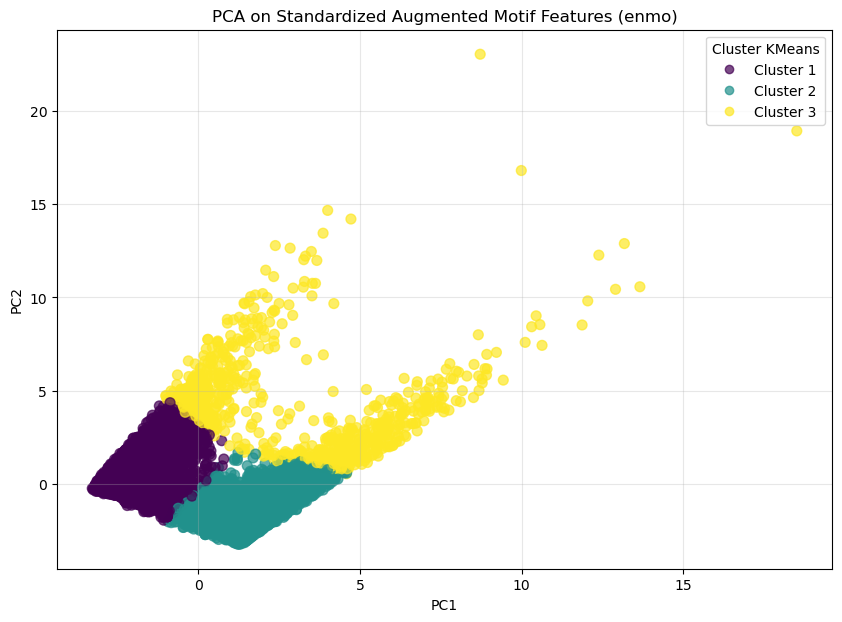


3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---
Retrieving real values from the original context of the motif:



,enmo_raw_mean,enmo_raw_std,anglez_raw_mean,anglez_raw_std,light_raw_mean,battery_mean,sii_binary
Cluster,,,,,,,
0,-0.212462,0.386280,-0.076032,0.491966,0.297498,0.267379,0.335818
1,-0.149129,0.430470,-0.021285,0.457403,0.302275,0.269894,0.346164
2,1.762890,2.352589,0.088971,0.346709,0.428987,0.277675,0.258917


- CLUSTER 1:
  * Real Intensity (ENMO): Mean -0.2125 | Std 0.3863
  * Real Posture (AngleZ): Mean -0.08° | Std 0.49
  * Ambient Light (Light): 0.297
  * Problematic Internet Use Correlation: 33.6% problematic cases
- CLUSTER 2:
  * Real Intensity (ENMO): Mean -0.1491 | Std 0.4305
  * Real Posture (AngleZ): Mean -0.02° | Std 0.46
  * Ambient Light (Light): 0.302
  * Problematic Internet Use Correlation: 34.6% problematic cases
- CLUSTER 3:
  * Real Intensity (ENMO): Mean 1.7629 | Std 2.3526
  * Real Posture (AngleZ): Mean 0.09° | Std 0.35
  * Ambient Light (Light): 0.429
  * Problematic Internet Use Correlation: 25.9% problematic cases



In [28]:
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy

# Analizziamo un subset per rapidità (o l'intero dataset rimuovendo lo slicing)
subset_ts = ts_denoised

for target_feature in target_features:
    print(f"\n{'='*70}\nSTRATEGY B: DYNAMIC EXTRACTION AND LOCAL CLUSTERING (SHAPE-BASED)\nANCHOR FEATURE: {target_feature}\n{'='*70}\n")
    
    motif_shapes_dataset = []  # Conterrà i vettori di feature aumentati
    motif_shapes_z_only = []   # Conterrà solo i motivi normalizzati per visualizzarli
    motif_context_dataset = []
    
    print(f"1. Dynamic extraction and Local Normalization (Z-score) of Top-{top_k_motifs} Motifs...")

    for i, ts_df in enumerate(subset_ts):
        ts_val = ts_df[target_feature].values.astype(np.float64)
        if len(ts_val) <= m:
            continue
            
        # Calcolo del Matrix Profile
        mp_local = stumpy.stump(ts_val, m)
        mp_dist = mp_local[:, 0].copy().astype(np.float64)
        
        # Ciclo di estrazione Top-K Motif
        for k in range(top_k_motifs):
            if np.isinf(mp_dist).all():
                break
                
            m_idx = np.argmin(mp_dist)
            motif_subseq = ts_val[m_idx : m_idx + m].copy()
            
            if not np.isnan(motif_subseq).any() and not np.isinf(mp_dist[m_idx]):
                # Standardizzazione locale (Z-score) del motivo per catturare la forma pura
                m_mean = np.mean(motif_subseq)
                m_std = np.std(motif_subseq)
                motif_z = (motif_subseq - m_mean) / m_std if m_std > 1e-8 else np.zeros_like(motif_subseq)
                
                # Calcolo dei 7 descrittori statistici/morfologici come descritto nel report
                mp_distance = mp_dist[m_idx]
                mean_val = m_mean
                std_val = m_std
                min_val = np.min(motif_subseq)
                max_val = np.max(motif_subseq)
                range_val = max_val - min_val
                slope_val = np.polyfit(np.arange(m), motif_subseq, 1)[0] if m > 1 else 0.0
                
                # Rappresentazione aumentata: forma normalizzata (m valori) + 7 descrittori
                augmented_features = np.concatenate([
                    motif_z,
                    [mp_distance, mean_val, std_val, min_val, max_val, range_val, slope_val]
                ])
                
                motif_shapes_dataset.append(augmented_features)
                motif_shapes_z_only.append(motif_z)
                
                # SALVATAGGIO CONTESTO REALE (per profilazione clinica multivariata)
                motif_raw_df = ts_df.iloc[m_idx : m_idx + m]
                context = {
                    'enmo_raw_mean': motif_raw_df['enmo'].mean() if 'enmo' in motif_raw_df.columns else np.nan,
                    'enmo_raw_std': motif_raw_df['enmo'].std() if 'enmo' in motif_raw_df.columns else np.nan,
                    'anglez_raw_mean': motif_raw_df['anglez'].mean() if 'anglez' in motif_raw_df.columns else np.nan,
                    'anglez_raw_std': motif_raw_df['anglez'].std() if 'anglez' in motif_raw_df.columns else np.nan,
                    'light_raw_mean': motif_raw_df['light'].mean() if 'light' in motif_raw_df.columns else np.nan,
                    'battery_mean': motif_raw_df['battery_voltage'].mean() if 'battery_voltage' in motif_raw_df.columns else np.nan,
                    'sii_binary': motif_raw_df['sii_binary'].iloc[0] if 'sii_binary' in motif_raw_df.columns else np.nan
                }
                motif_context_dataset.append(context)
                
            # Exclusion zone logic
            excl_start = max(0, m_idx - int(np.ceil(m/2)))
            excl_end = min(len(mp_dist), m_idx + int(np.ceil(m/2)))
            mp_dist[excl_start:excl_end] = np.inf
            
            nn_idx = mp_local[m_idx, 1]
            if nn_idx >= 0:
                excl_nn_start = max(0, nn_idx - int(np.ceil(m/2)))
                excl_nn_end = min(len(mp_dist), nn_idx + int(np.ceil(m/2)))
                mp_dist[excl_nn_start:excl_nn_end] = np.inf

    motif_shapes_dataset = np.array(motif_shapes_dataset)
    motif_shapes_z_only = np.array(motif_shapes_z_only)
    df_context = pd.DataFrame(motif_context_dataset)
    print(f"Created dataset of {motif_shapes_dataset.shape[0]} augmented motif feature vectors (dimension: {motif_shapes_dataset.shape[1]}) for {target_feature}.")

    # Standardizzazione globale di tutte le feature prima del clustering (come specificato nel report)
    scaler = StandardScaler()
    X_clust = scaler.fit_transform(motif_shapes_dataset)

    # CLUSTERING FEATURE-BASED (KMeans standard con distanza Euclidea)
    print(f"\n2. Executing KMeans Feature-Based (K={k_clusters_motif}) with Euclidean distance...")
    kmeans = KMeans(n_clusters=k_clusters_motif, n_init=10, random_state=42)
    motif_clusters = kmeans.fit_predict(X_clust)
    df_context['Cluster'] = motif_clusters

    # VISUALIZZAZIONE DELLE MORFOLOGIE MEDIE (Pointwise Mean e Deviazione Standard)
    fig, axs = plt.subplots(k_clusters_motif, 1, figsize=(10, 8), sharex=True)
    fig.suptitle(f"Average Motif Profile by Cluster anchored on '{target_feature}' (m = {m})", fontsize=14)
    
    for i in range(k_clusters_motif):
        cluster_mask = (motif_clusters == i)
        cluster_shapes = motif_shapes_z_only[cluster_mask]
        
        # Calcolo pointwise mean e std dei motivi localmente standardizzati
        mean_profile = np.mean(cluster_shapes, axis=0)
        std_profile = np.std(cluster_shapes, axis=0)
        
        axs[i].plot(mean_profile, color='crimson', linewidth=2, label='Mean Profile')
        axs[i].fill_between(range(m), mean_profile - std_profile, mean_profile + std_profile, color='crimson', alpha=0.15, label='±1 Std Dev')
        axs[i].set_title(f'Cluster {i+1} (n = {sum(cluster_mask)})')
        axs[i].grid(True, alpha=0.3)
        axs[i].legend(loc='upper right')
        
    plt.tight_layout()
    plt.show()

    # PCA 2D
    pca = PCA(n_components=2)
    motif_pca = pca.fit_transform(X_clust)
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(motif_pca[:, 0], motif_pca[:, 1], c=motif_clusters, cmap='viridis', alpha=0.7, s=50)
    handles, _ = scatter.legend_elements()
    plt.legend(handles, [f"Cluster {i+1}" for i in range(k_clusters_motif)], title="Cluster KMeans")
    plt.title(f"PCA on Standardized Augmented Motif Features ({target_feature})")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(True, alpha=0.3)
    plt.show()

    # PROFILING MULTIVARIATO
    print(f"\n3. --- MULTIVARIATE CLINICAL INTERPRETATION OF SHAPE CLUSTERS ---")
    print("Retrieving real values from the original context of the motif:\n")
    
    cluster_profiles = df_context.groupby('Cluster').mean()
    display(cluster_profiles)
    
    for i, row in cluster_profiles.iterrows():
        print(f"- CLUSTER {i+1}:")
        if 'enmo_raw_mean' in row:
            print(f"  * Real Intensity (ENMO): Mean {row['enmo_raw_mean']:.4f} | Std {row.get('enmo_raw_std', 0):.4f}")
        if 'anglez_raw_mean' in row:
            print(f"  * Real Posture (AngleZ): Mean {row['anglez_raw_mean']:.2f}° | Std {row.get('anglez_raw_std', 0):.2f}")
        if 'light_raw_mean' in row:
            print(f"  * Ambient Light (Light): {row['light_raw_mean']:.3f}")
        if 'sii_binary' in row and not np.isnan(row['sii_binary']):
            print(f"  * Problematic Internet Use Correlation: {row['sii_binary']*100:.1f}% problematic cases")
    print()


## Fase 2: Estrazione con RDST e Classificazione con Feature Fusion

Implementiamo un approccio di **Late Concatenation / Feature-level Fusion** in tre fasi distinte:

1. **Trasformazione con `RandomDilatedShapeletTransform`**: estraiamo le feature temporali dai canali dinamici. RDST genera per ogni shapelet 3 feature scalari: distanza minima, posizione temporale (argmin) e frequenza.
2. **Feature Fusion**: concateniamo il vettore RDST con le variabili statiche originali scalari (`battery_voltage`, `weekday`, `quarter`, `relative_date_PCIAT`).
3. **Classificatore Decision Tree standard**: addestriamo un albero di decisione su questo dataset eterogeneo combinato.

> **Nota metodologica**: si usa direttamente `RandomDilatedShapeletTransform` (trasformatore) e non `RDSTClassifier` (pipeline trasformatore + Ridge), evitando spreco computazionale di addestrare un classificatore intermedio poi scartato.

In [37]:
# --- PREPARAZIONE DEI DATI ---------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, roc_auc_score, balanced_accuracy_score
)
from sklearn.inspection import permutation_importance
from aeon.transformations.collection.shapelet_based import RandomDilatedShapeletTransform

# Canali dinamici (serie temporali) escluse le variabili statiche e di metadato
colonne_metadati = [
    'id', 'sii_binary', 'weekday', 'quarter',
    'relative_date_PCIAT', 'non-wear_flag', 'battery_voltage'
]
static_cols = ['battery_voltage', 'weekday', 'quarter', 'relative_date_PCIAT']
cols_to_use = [col for col in ts_denoised[0].columns if col not in colonne_metadati]
print(f"Canali dinamici per RDST: {cols_to_use}")
print(f"Variabili statiche per la fusione: {static_cols}")

# Array 3D delle serie temporali dinamiche: (n_serie, n_canali, n_timesteps)
X_ts = np.array([
    np.stack([df[col].values.astype(np.float64) for col in cols_to_use], axis=0)
    for df in ts_denoised
])

# Variabili statiche: valore scalare al primo timestep (costante per serie)
X_static_all = np.array([
    df[static_cols].iloc[0].values.astype(np.float64)
    for df in ts_denoised
])

y = np.array([df['sii_binary'].iloc[0] for df in ts_denoised])

# Split stratificato 70/30 coerente su entrambe le matrici
indices = np.arange(len(ts_denoised))
train_idx, test_idx = train_test_split(indices, test_size=0.3, random_state=222, stratify=y)

X_train_ts, X_test_ts = X_ts[train_idx], X_ts[test_idx]
X_train_static, X_test_static = X_static_all[train_idx], X_static_all[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

n_ts, n_ch, ts_len = X_ts.shape
print(f"\nDataset: {n_ts} serie, {n_ch} canali dinamici, lunghezza {ts_len} timestep")
print(f"Train: {len(train_idx)} | Test: {len(test_idx)}")
print(f"Distribuzione classi (train): {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Distribuzione classi (test):  {dict(zip(*np.unique(y_test, return_counts=True)))}")


Canali dinamici per RDST: ['X', 'Y', 'Z', 'enmo', 'anglez', 'light']
Variabili statiche per la fusione: ['battery_voltage', 'weekday', 'quarter', 'relative_date_PCIAT']

Dataset: 4437 serie, 6 canali dinamici, lunghezza 200 timestep
Train: 3105 | Test: 1332
Distribuzione classi (train): {np.int64(0): np.int64(2069), np.int64(1): np.int64(1036)}
Distribuzione classi (test):  {np.int64(0): np.int64(888), np.int64(1): np.int64(444)}


### Tuning di RandomDilatedShapeletTransform e Costruzione del Dataset Combinato

In [38]:
# --- ESTRAZIONE FEATURE CON RANDOMDILATEDSHAPELETTRANSFORM --------------------
# Usiamo direttamente il TRASFORMATORE (non RDSTClassifier) per evitare di
# addestrare un classificatore Ridge intermedio che poi scarteremmo.
rdst = RandomDilatedShapeletTransform(
    max_shapelets=1000,
    shapelet_lengths=[4, 8, 12, 16],
    use_prime_dilations=True,
    random_state=222,
    n_jobs=-1
)

print("Estrazione delle shapelets con RDST (fit_transform su train)...")
X_train_sh = rdst.fit_transform(X_train_ts, y_train)

print("Trasformazione del test set...")
X_test_sh = rdst.transform(X_test_ts)

actual_k = X_train_sh.shape[1] // 3
print(f"Shapelet estratte: {actual_k} (feature totali RDST: {X_train_sh.shape[1]})")

# --- FEATURE FUSION: concatenazione con le variabili statiche -----------------
X_train_combined = np.hstack([X_train_sh, X_train_static])
X_test_combined = np.hstack([X_test_sh, X_test_static])

# Nomi delle feature: 3 per shapelet + variabili statiche
feature_names = []
for i in range(actual_k):
    feature_names.extend([
        f"Shapelet_{i}_MinDist",
        f"Shapelet_{i}_Argmin",
        f"Shapelet_{i}_Freq"
    ])
feature_names.extend(static_cols)

print(f"\nDataset combinato (Train): {X_train_combined.shape}")
print(f"Dataset combinato (Test): {X_test_combined.shape}")
print(f"Totale feature: {len(feature_names)} "
      f"(di cui {actual_k * 3} da RDST + {len(static_cols)} statiche)")


Estrazione delle shapelets con RDST (fit_transform su train)...
Trasformazione del test set...
Shapelet estratte: 1000 (feature totali RDST: 3000)

Dataset combinato (Train): (3105, 3004)
Dataset combinato (Test): (1332, 3004)
Totale feature: 3004 (di cui 3000 da RDST + 4 statiche)


In [39]:
# --- TUNING DEL RANDOM FOREST CON RandomizedSearchCV -----------------------
# Sul dataset combinato (feature RDST + variabili statiche) applichiamo una
# RandomizedSearchCV per trovare la configurazione ottimale del RandomForest.
# Ottimizziamo la macro F1 per tenere conto dello sbilanciamento 2:1 tra classi.

from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(
    random_state=222,
    class_weight='balanced',
    n_jobs=-1
)

param_dist_rf = {
    'n_estimators':      [50, 100, 150],
    'max_depth':         [5, 7, 10, None],
    'min_samples_split': [5, 10, 20],
    'min_samples_leaf':  [8, 16, 32],
    'criterion':         ['gini', 'entropy'],
    'max_features':      ['sqrt', 'log2', None]
}

random_search_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist_rf,
    n_iter=15,
    cv=3,
    scoring='f1_macro',
    random_state=222,
    n_jobs=-1,
    verbose=1,
    refit=True
)

print("Inizio tuning Random Forest (15 iter, 3-fold CV, scoring=f1_macro)...")
random_search_rf.fit(X_train_combined, y_train)

print("\n" + "="*55)
print("MIGLIORI IPERPARAMETRI RANDOM FOREST:")
print("="*55)
for param, value in random_search_rf.best_params_.items():
    print(f'  {param}: {value}')
print(f'\nMiglior F1-Macro in CV: {random_search_rf.best_score_:.4f}')
print("="*55)

combined_rf = random_search_rf.best_estimator_


Inizio tuning Random Forest (15 iter, 3-fold CV, scoring=f1_macro)...
Fitting 3 folds for each of 15 candidates, totalling 45 fits

MIGLIORI IPERPARAMETRI RANDOM FOREST:
  n_estimators: 150
  min_samples_split: 10
  min_samples_leaf: 32
  max_features: None
  max_depth: 7
  criterion: entropy

Miglior F1-Macro in CV: 0.6280


=== CLASSIFICATION REPORT (TEST SET — Random Forest su Dataset Combinato) ===
              precision    recall  f1-score   support

    Low Risk       0.80      0.75      0.77       888
   High Risk       0.56      0.63      0.59       444

    accuracy                           0.71      1332
   macro avg       0.68      0.69      0.68      1332
weighted avg       0.72      0.71      0.71      1332

ROC AUC:           0.7453
Balanced Accuracy: 0.6892


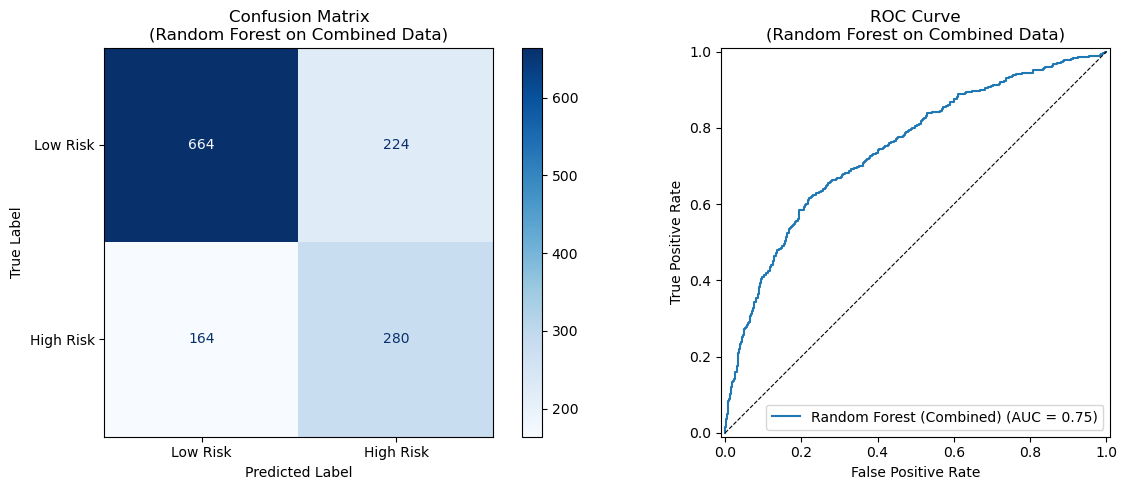

In [40]:
# --- CLASSIFICAZIONE E VALUTAZIONE SUL TEST SET COMBINATO --------------------
# combined_rf è il best_estimator_ trovato dalla RandomizedSearchCV in cell 15
y_pred = combined_rf.predict(X_test_combined)
y_proba = combined_rf.predict_proba(X_test_combined)[:, 1]

print("=== CLASSIFICATION REPORT (TEST SET — Random Forest su Dataset Combinato) ===")
print(classification_report(y_test, y_pred, target_names=["Low Risk", "High Risk"]))

roc_auc = roc_auc_score(y_test, y_proba)
bal_acc = balanced_accuracy_score(y_test, y_pred)
print(f"ROC AUC:           {roc_auc:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_estimator(
    combined_rf, X_test_combined, y_test,
    display_labels=["Low Risk", "High Risk"],
    cmap='Blues', ax=axes[0]
)
axes[0].set_title("Confusion Matrix\n(Random Forest on Combined Data)", fontsize=12)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

RocCurveDisplay.from_estimator(
    combined_rf, X_test_combined, y_test, ax=axes[1],
    name="Random Forest (Combined)"
)
axes[1].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
axes[1].set_title("ROC Curve\n(Random Forest on Combined Data)", fontsize=12)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()


In [41]:
# --- VISUALIZZAZIONE STRUTTURA ALBERO RIMOSSA --------------------------------
print("Visualizzazione dell'albero non applicabile per Random Forest.")


Visualizzazione dell'albero non applicabile per Random Forest.


In [42]:
# --- PERMUTATION FEATURE IMPORTANCE (sul test set) ----------------------------
# Calcolo della Permutation Feature Importance per identificare le feature chiave
# per la generalizzazione del Random Forest sul test set. I grafici sono stati omessi.

print("Calcolo Permutation Feature Importance sul test set (n_repeats=10)...\n")
perm_imp = permutation_importance(
    combined_rf,
    X_test_combined, y_test,
    n_repeats=10,
    random_state=222,
    scoring='f1_macro',
    n_jobs=-1
)

perm_means = perm_imp.importances_mean
perm_stds = perm_imp.importances_std

top_n = min(20, len(feature_names))
top_feature_idx = np.argsort(perm_means)[::-1][:top_n]

# Stampa testuale della graduatoria
print("--- GRADUATORIA PERMUTATION IMPORTANCE (Top feature per generalizzazione) ---")
for rank, idx in enumerate(top_feature_idx):
    marker = '[STATIC]' if feature_names[idx] in static_cols else '[SHAPELET]'
    print(f"  Rank {rank+1:02d}: {feature_names[idx]:<30} | {perm_means[idx]:+.4f} \u00b1 {perm_stds[idx]:.4f}  {marker}")

# --- PONTE INTERPRETATIVO CON CELL 19 -----------------------------------------
# Identificazione della shapelet RDST più importante per la Fase 3
shapelet_perm = np.zeros(actual_k)
for sh_idx in range(actual_k):
    shapelet_perm[sh_idx] = np.sum(perm_means[3 * sh_idx : 3 * sh_idx + 3])

best_sh_idx = np.argsort(shapelet_perm)[::-1][0]
shapelets_top = [rdst.shapelets_[0][best_sh_idx]]
cols_to_use = cols_to_use


Calcolo Permutation Feature Importance sul test set (n_repeats=10)...

--- GRADUATORIA PERMUTATION IMPORTANCE (Top feature per generalizzazione) ---
  Rank 01: relative_date_PCIAT            | +0.0438 ± 0.0074  [STATIC]
  Rank 02: Shapelet_317_MinDist           | +0.0140 ± 0.0037  [SHAPELET]
  Rank 03: Shapelet_844_Freq              | +0.0120 ± 0.0075  [SHAPELET]
  Rank 04: Shapelet_539_MinDist           | +0.0075 ± 0.0031  [SHAPELET]
  Rank 05: Shapelet_161_MinDist           | +0.0054 ± 0.0027  [SHAPELET]
  Rank 06: Shapelet_883_Freq              | +0.0044 ± 0.0025  [SHAPELET]
  Rank 07: quarter                        | +0.0028 ± 0.0029  [STATIC]
  Rank 08: Shapelet_900_MinDist           | +0.0028 ± 0.0048  [SHAPELET]
  Rank 09: Shapelet_703_Freq              | +0.0024 ± 0.0020  [SHAPELET]
  Rank 10: Shapelet_916_Freq              | +0.0022 ± 0.0017  [SHAPELET]
  Rank 11: Shapelet_757_MinDist           | +0.0019 ± 0.0022  [SHAPELET]
  Rank 12: Shapelet_908_MinDist           | +0.0018 

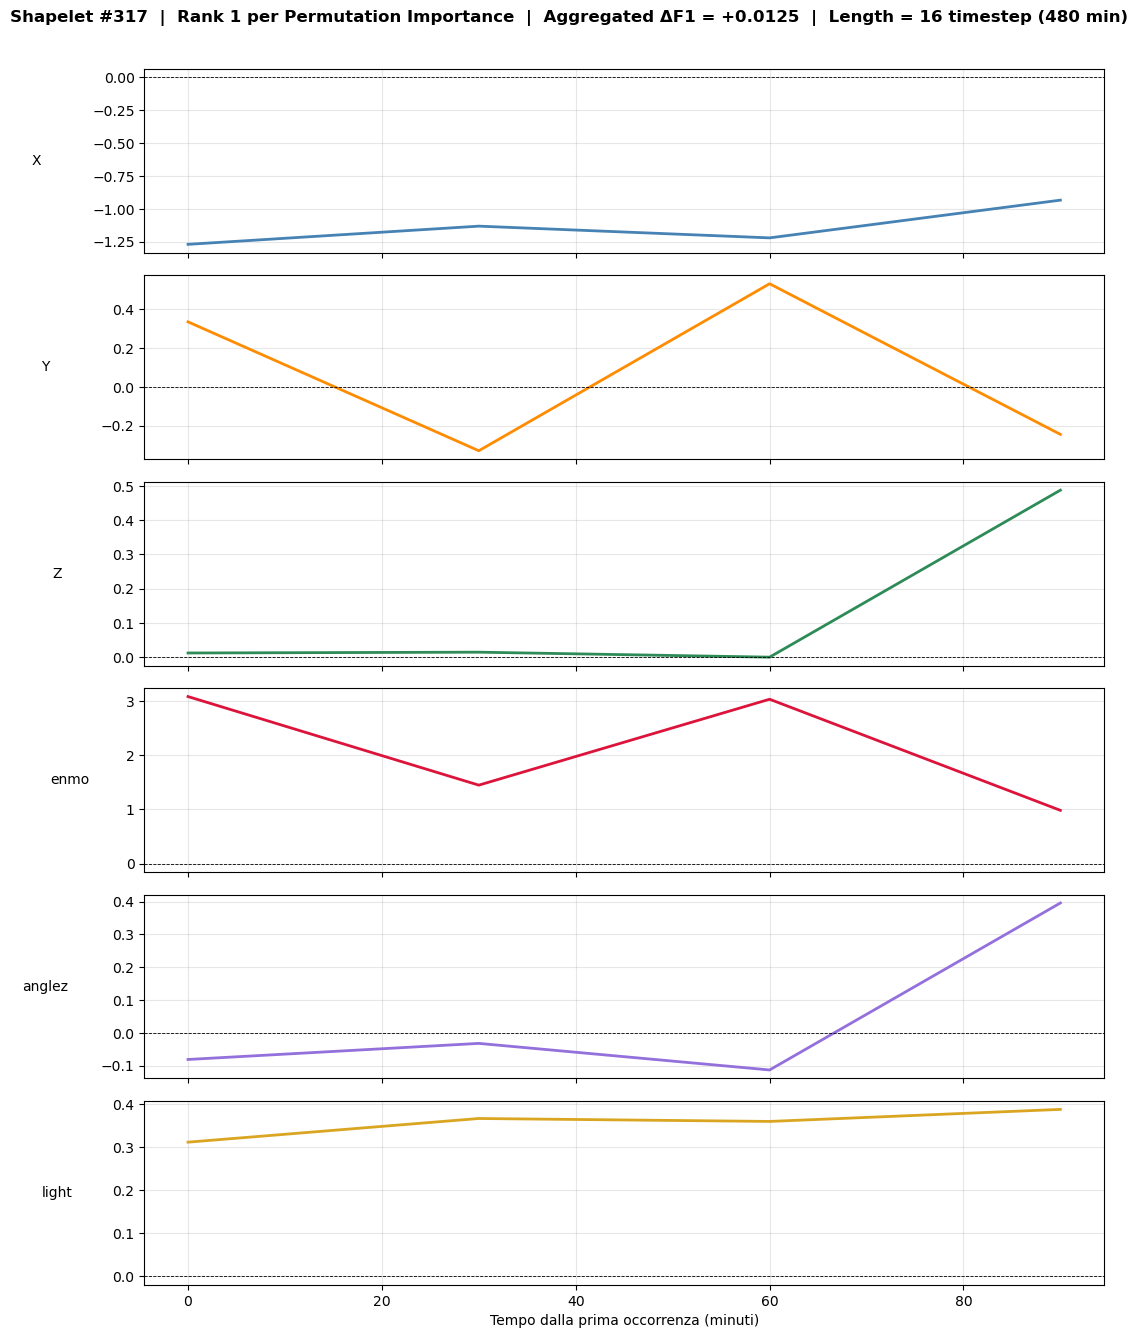

Shapelet #317: length=16 step (480 min) | Aggregated PFI = +0.0125
  X          min=-1.270  max=inf  range=inf
  Y          min=-0.329  max=inf  range=inf
  Z          min=-0.000  max=inf  range=inf
  enmo       min=0.982  max=inf  range=inf
  anglez     min=-0.113  max=inf  range=inf
  light      min=0.312  max=inf  range=inf



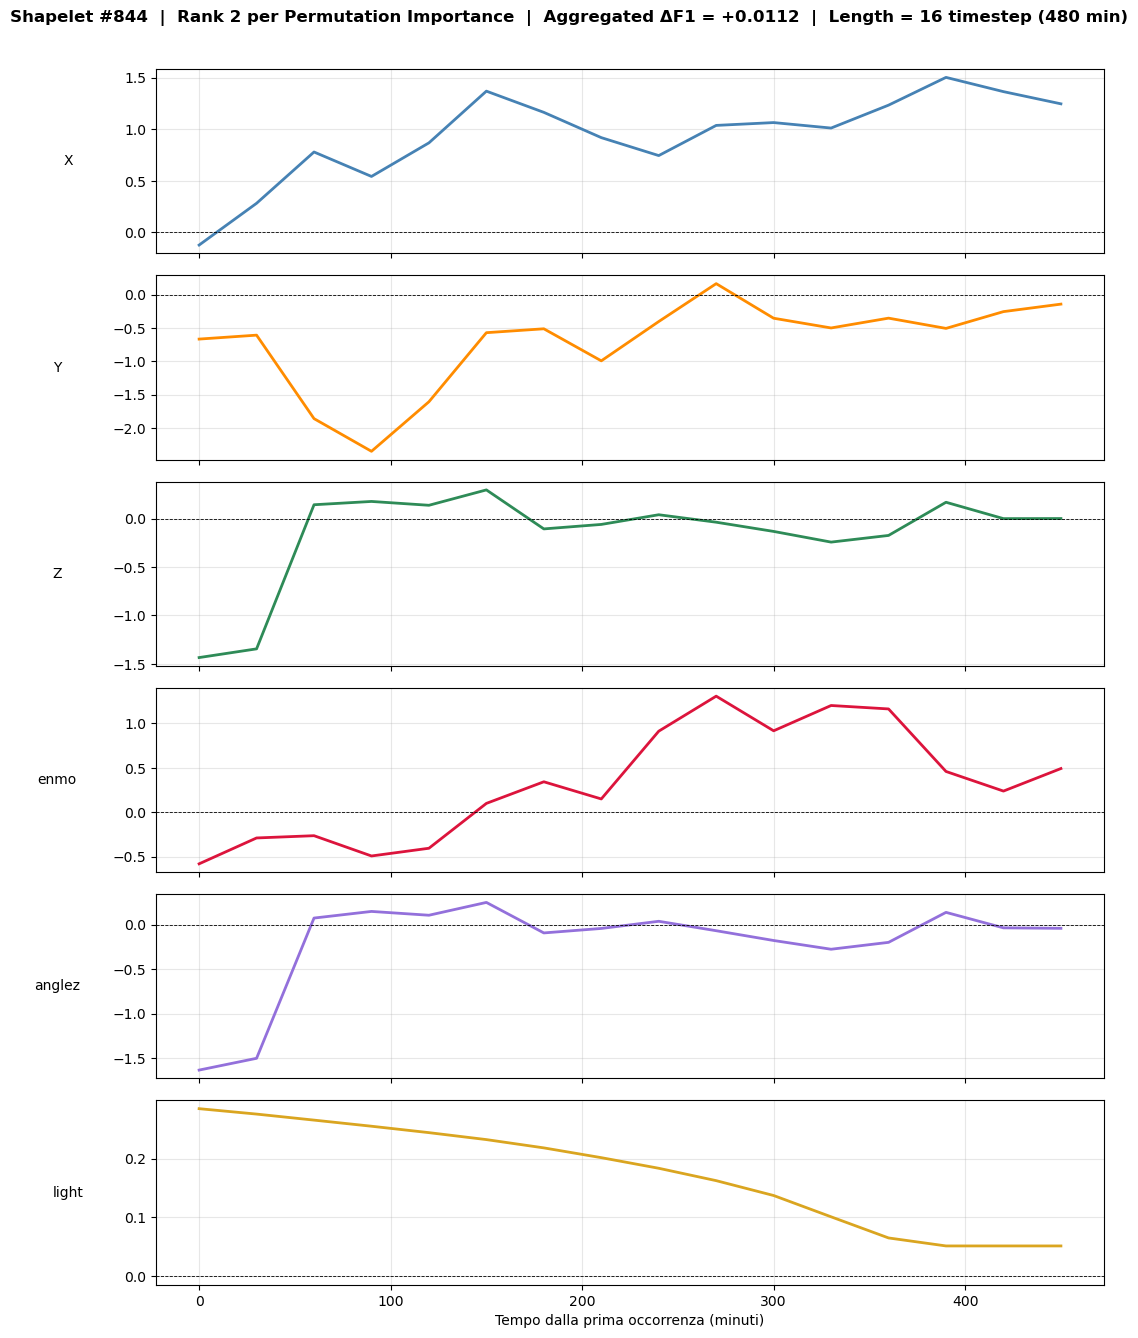

Shapelet #844: length=16 step (480 min) | Aggregated PFI = +0.0112
  X          min=-0.122  max=1.503  range=1.625
  Y          min=-2.348  max=0.165  range=2.513
  Z          min=-1.435  max=0.297  range=1.732
  enmo       min=-0.580  max=1.307  range=1.888
  anglez     min=-1.632  max=0.251  range=1.883
  light      min=0.052  max=0.285  range=0.233



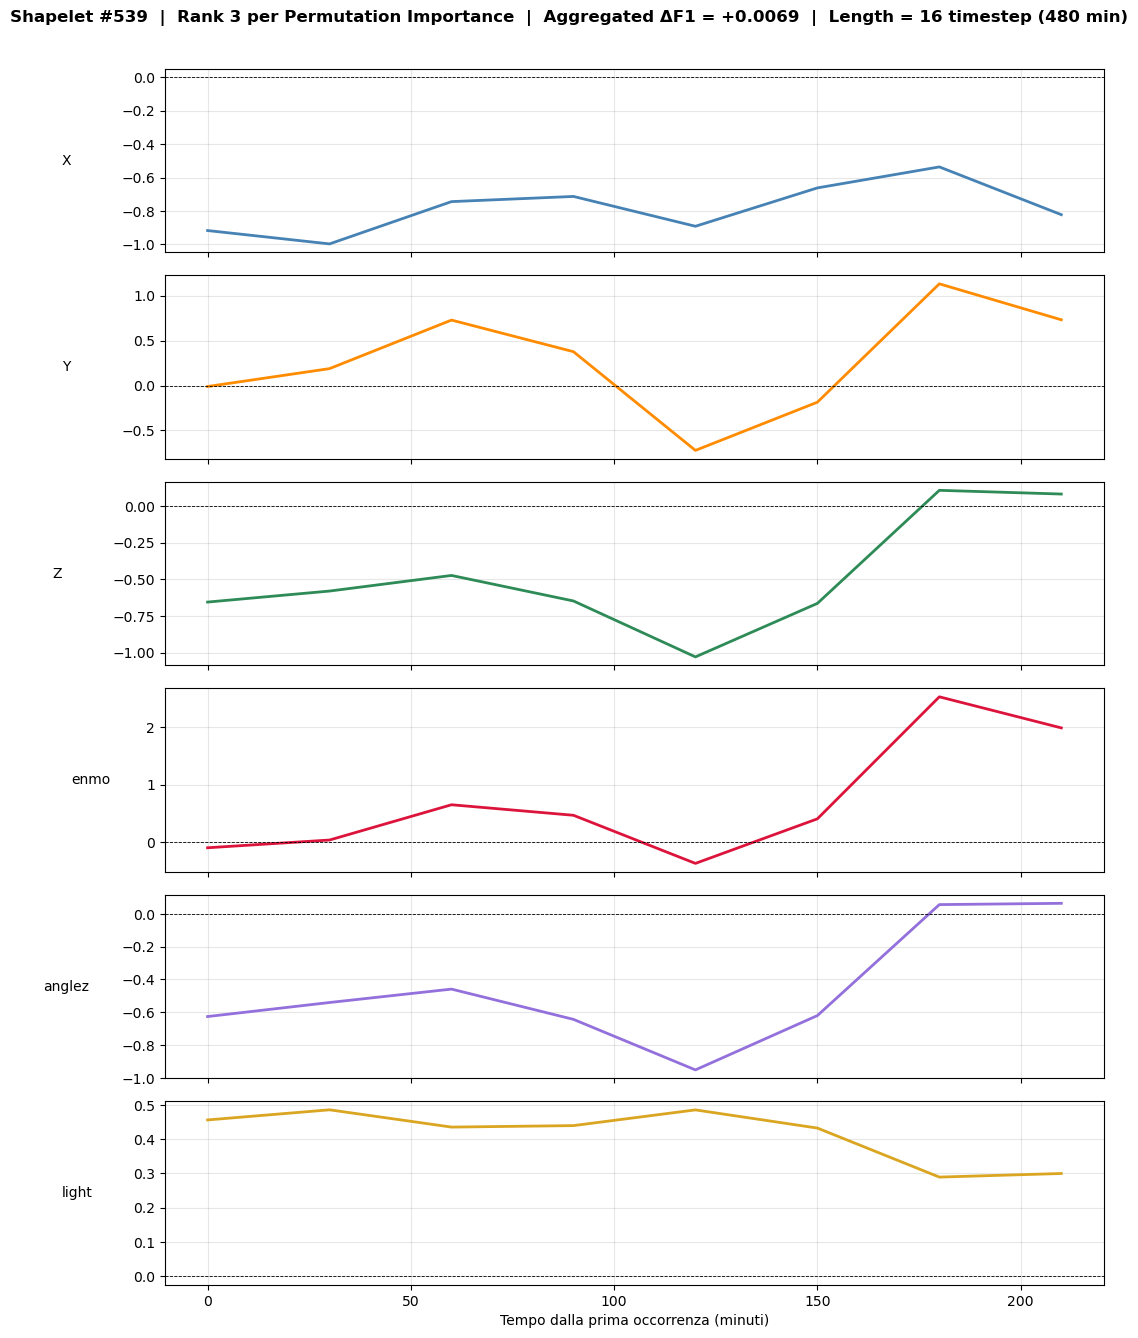

Shapelet #539: length=16 step (480 min) | Aggregated PFI = +0.0069
  X          min=-0.997  max=inf  range=inf
  Y          min=-0.722  max=inf  range=inf
  Z          min=-1.029  max=inf  range=inf
  enmo       min=-0.365  max=inf  range=inf
  anglez     min=-0.951  max=inf  range=inf
  light      min=0.289  max=inf  range=inf



In [43]:
# --- VISUALIZZAZIONE DELLA SHAPELET PIÙ DISCRIMINANTE (tutti i canali) ------
# best_sh_idx è stato calcolato in cella precedente aggregando i 3 contributi PFI
# (MinDist, Argmin, Freq) della stessa shapelet.
# rdst.shapelets_[0] → lista delle shapelets estratte;
# ogni shapelet è un array (n_channels, shapelet_length).

top3_idx = np.argsort(shapelet_perm)[::-1][:3]

n_channels = len(cols_to_use)
channel_colors = ['steelblue', 'darkorange', 'seagreen', 'crimson', 'mediumpurple', 'goldenrod']

for rank, sh_idx in enumerate(top3_idx):
    sh = rdst.shapelets_[0][sh_idx]   # shape: (n_channels, shapelet_length)
    sh_len = sh.shape[1]
    agg_importance = shapelet_perm[sh_idx]

    fig, axes = plt.subplots(n_channels, 1, figsize=(11, 2.2 * n_channels), sharex=True)
    fig.suptitle(
        f"Shapelet #{sh_idx}  |  Rank {rank+1} per Permutation Importance"
        f"  |  Aggregated ΔF1 = {agg_importance:+.4f}"
        f"  |  Length = {sh_len} timestep ({sh_len * 30} min)",
        fontsize=12, fontweight='bold', y=1.01
    )

    t_axis = np.arange(sh_len) * 30  # asse in minuti
    for ch_i, (ax, ch_name) in enumerate(zip(axes, cols_to_use)):
        ax.plot(t_axis, sh[ch_i], color=channel_colors[ch_i % len(channel_colors)],
                linewidth=2)
        ax.set_ylabel(ch_name, fontsize=10, rotation=0, labelpad=40, va='center')
        ax.grid(alpha=0.3)
        ax.axhline(0, color='black', linewidth=0.6, linestyle='--')

    axes[-1].set_xlabel("Tempo dalla prima occorrenza (minuti)", fontsize=10)
    plt.tight_layout()
    plt.show()

    print(f"Shapelet #{sh_idx}: length={sh_len} step ({sh_len*30} min) | "
          f"Aggregated PFI = {agg_importance:+.4f}")
    for ch_i, ch_name in enumerate(cols_to_use):
        ch_vals = sh[ch_i]
        print(f"  {ch_name:<10} min={ch_vals.min():.3f}  max={ch_vals.max():.3f}  "
              f"range={ch_vals.max()-ch_vals.min():.3f}")
    print()


## Fase 3: Ponte Interpretativo — Shapelet vs Motif sui Medoidi

Confrontiamo la firma discriminatoria **globale** (Shapelet estratto su tutto il dataset)
con il pattern **locale** (Motif) e l'anomalia locale (Discord) estratti con Matrix Profile
dai medoidi del clustering.

Questo collegamento e' richiesto esplicitamente dalle linee guida del progetto
e risponde alla domanda: *il pattern ricorrente locale di un soggetto
corrisponde alla firma discriminativa globale della sua classe?*

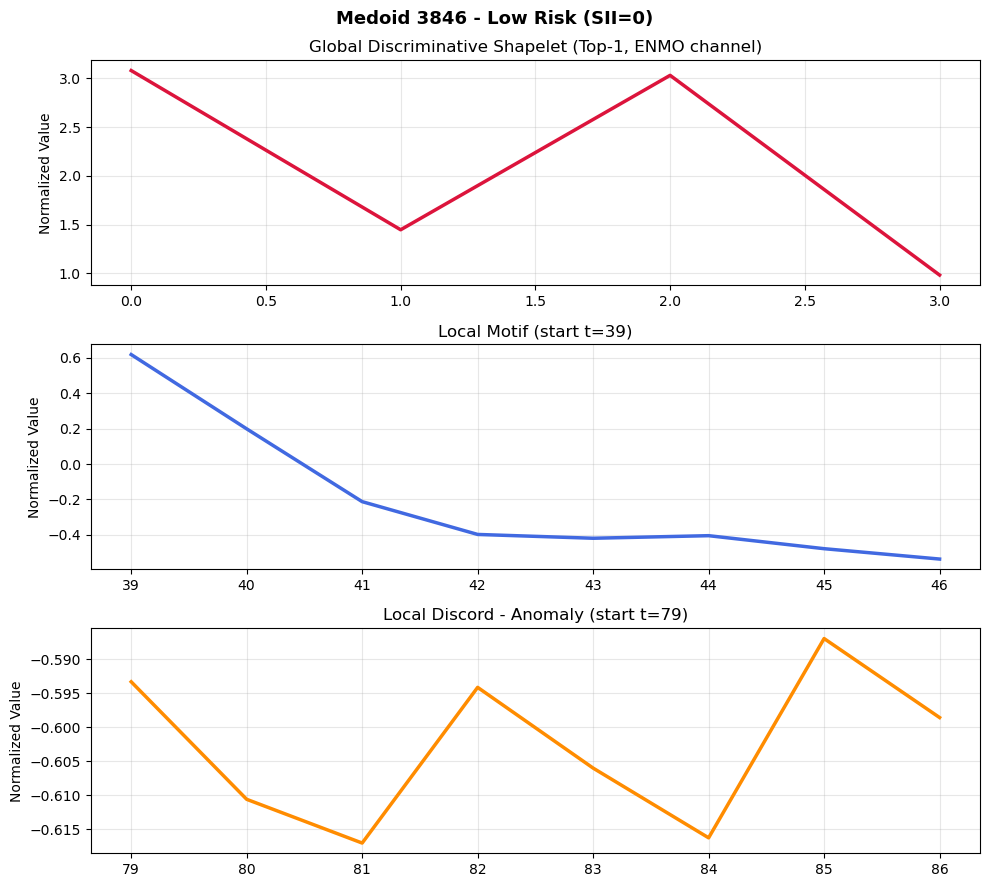

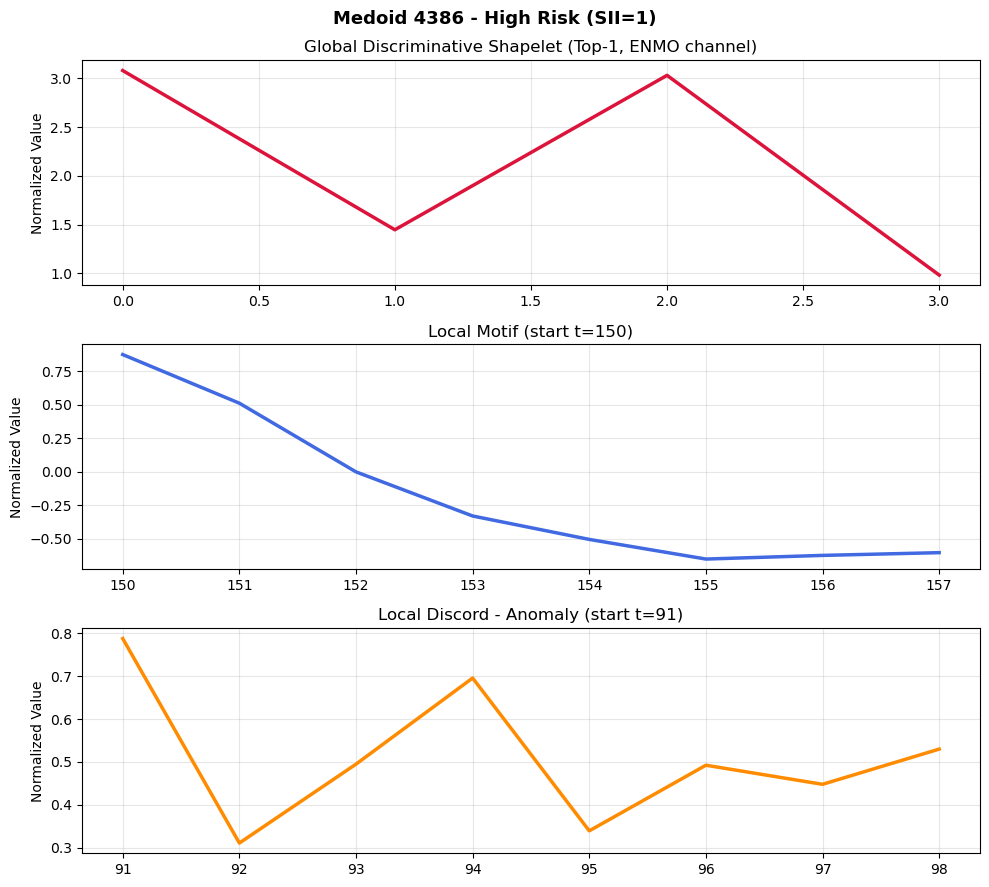

Exception ignored in: <function ResourceTracker.__del__ at 0x105f2dc60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104c65c60>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x105019c60>
Traceback (most recent call last

In [44]:
import stumpy

# m_bridge coerente con la window size usata nella sezione Motif
m_bridge = m  # definita nella sezione motifs (Cell 6)

if 'shapelets_top' in locals() and len(shapelets_top) > 0 and 'medoid_idx' in locals():
    enmo_ch = cols_to_use.index('enmo')

    for subj_idx in medoid_idx:
        ts_enmo = X[subj_idx, enmo_ch, :].astype(np.float64)
        label   = "High Risk (SII=1)" if y[subj_idx] == 1 else "Low Risk (SII=0)"

        mp            = stumpy.stump(ts_enmo, m_bridge)
        motif_idx_s   = int(mp[:, 0].argmin())
        discord_idx_s = int(mp[:, 0].argmax())

        top_motif   = ts_enmo[motif_idx_s   : motif_idx_s   + m_bridge]
        top_discord = ts_enmo[discord_idx_s : discord_idx_s + m_bridge]
        top_sh_enmo = shapelets_top[0][enmo_ch]  # shapelet top-1, canale ENMO

        fig, axs = plt.subplots(3, 1, figsize=(10, 9))
        fig.suptitle(f"Medoid {subj_idx} - {label}", fontsize=13, fontweight='bold')

        axs[0].plot(top_sh_enmo, color='crimson', linewidth=2.5)
        axs[0].set_title("Global Discriminative Shapelet (Top-1, ENMO channel)")
        axs[0].set_ylabel("Normalized Value")

        axs[1].plot(range(motif_idx_s, motif_idx_s + m_bridge), top_motif,
                    color='royalblue', linewidth=2.5)
        axs[1].set_title(f"Local Motif (start t={motif_idx_s})")
        axs[1].set_ylabel("Normalized Value")

        axs[2].plot(range(discord_idx_s, discord_idx_s + m_bridge), top_discord,
                    color='darkorange', linewidth=2.5)
        axs[2].set_title(f"Local Discord - Anomaly (start t={discord_idx_s})")
        axs[2].set_ylabel("Normalized Value")

        for ax in axs:
            ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
else:
    print("Please run Phase 2 (shapelets) and Phase 1 (motifs) first.")

### Commento ai Risultati

#### Correttezza Metodologica
1. **Dati dataset-wise normalizzati**: la standardizzazione dataset-wise preserva le differenze di intensita' tra soggetti, cruciale perche' `sii` e' correlato all'intensita' assoluta dell'attivita' fisica.
2. **RDST vs brute-force**: RDST usa dilatazioni random per esplorare uno spazio temporale ampio senza enumerare tutti i candidati, rendendo l'estrazione praticabile sull'intero dataset non approssimato.
3. **Classi sbilanciate**: `class_weight='balanced'` e ottimizzazione su F1-Macro garantiscono che il modello non collassi sulla classe maggioritaria.
4. **Tre feature per shapelet**: distanza, posizione e frequenza descrivono non solo *quanto* una forma e' simile, ma *dove* e *quante volte* appare.

#### Interpretazione degli Shapelet
- **Distanza minima**: cattura la *presenza* della forma (il soggetto ha mai avuto quella firma energetica?).
- **Posizione (argmin)**: cattura la *fase circadiana* (lo stesso pattern alle 3:00 vs 15:00 ha significato biologico diverso).
- **Frequenza**: cattura l'*abitudine motoria* (pattern ripetuti = routine consolidate).

#### Limitazioni e Possibili Estensioni
- Il Decision Tree interno e' limitato nelle interazioni non lineari. Un passo naturale e' sostituirlo con Random Forest o GBM.
- Le serie non approssimate garantiscono ricchezza di dettaglio ma limitano il numero di shapelet testabili. Vedere `motifs_shapelets_corrected_paa.ipynb` per la versione PAA.